# 05 · Final Evaluation on the Later Time Period
### IT3091 Machine Learning · Group 2026-AI-42 · Evaluation, recommendation & documentation lead

**Question.** How does the chosen model perform on a *future* period it has never seen, and how much would a naive random split have overstated that?
**Input:** the tuned pipeline from notebook 04. **Output:** `reports/tables/holdout_results.csv`.

Every model is re-fitted on the **training period** and scored **once** on the later **test period**. The test period was not used for any selection or tuning decision; nothing is chosen from this table, so it stays honest evidence.

In [1]:
import sys, pathlib, warnings
ROOT = pathlib.Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))          # lets the notebook import the project code in src/
warnings.filterwarnings("ignore")

import json, joblib
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from IPython.display import display
from sklearn.base import clone
from sklearn.metrics import accuracy_score, average_precision_score, roc_auc_score
from sklearn.model_selection import TimeSeriesSplit, train_test_split

from src.config import *
from src.data.prepare import load_modelling_data
from src.evaluation.metrics import cv_eval, metric_row, scores_of, topk_metrics
from src.features.preprocessing import build_pipeline
from src.models.candidates import build_main_models, build_challenger_specs
from src.plotting import set_style, save_fig

set_style()
pd.set_option("display.max_columns", 60, "display.width", 170)
data = load_modelling_data()
X_train, y_train, X_test, y_test = data["X_train"], data["y_train"], data["X_test"], data["y_test"]
X_all, y_all = data["X_all"], data["y_all"]
best_pipe = joblib.load(ARTIFACTS_DIR / "tuned_pipeline.joblib")
TUNED_NAME = json.loads((ARTIFACTS_DIR / "tuned_params.json").read_text())["name"]
models = build_main_models()

Loading local file: bank-additional-full.csv
Rows: raw 41,188 -> cleaned 41,176 | train 32,940 (rate 6.38%) | pilot 500 | test 7,736 (rate 32.41%)


---
## 1 · Held-out results for the main models and the tuned model

In [2]:
final_models = dict(models); final_models[TUNED_NAME] = best_pipe
rows, test_scores = [], {}
for name, p in final_models.items():
    m = clone(p).fit(X_train, y_train)
    s = scores_of(m, X_test)
    test_scores[name] = s
    r = metric_row(y_test, s); r["accuracy_at_0_5"] = accuracy_score(y_test, (s >= 0.5).astype(int))
    rows.append(dict(model=name, **r))
holdout = pd.DataFrame(rows).set_index("model").round(3)
display(holdout)
holdout.to_csv(TABLES_DIR / "holdout_results.csv")
np.savez(ARTIFACTS_DIR / "test_scores.npz", **{k: v for k, v in test_scores.items()})
print(f"Test base rate: {y_test.mean():.3%}  | budget = contact the best-scored {CALL_BUDGET:.0%} of clients")

,roc_auc,pr_auc,precision_at_budget,recall_at_budget,lift_at_budget,accuracy_at_0_5
model,,,,,,
Dummy (prior),0.500,0.324,0.304,0.187,0.937,0.676
Logistic regression,0.691,0.502,0.559,0.345,1.725,0.548
Random forest,0.687,0.507,0.590,0.364,1.821,0.701
Hist. gradient boosting,0.659,0.463,0.531,0.328,1.640,0.597
MLP (64-32),0.717,0.563,0.639,0.394,1.971,0.676
Tuned Logistic regression,0.689,0.499,0.557,0.344,1.719,0.681


Test base rate: 32.407%  | budget = contact the best-scored 20% of clients


**Reading.** Compare each model with the dummy row: the dummy's PR-AUC *is* the base rate of the test period, so any model above it has learned something. Because the test period has a very different base rate from training (EDA §9), **do not compare PR-AUC across periods**: compare **lift** and ROC-AUC. The global ROC-AUC mixes two skills: telling *periods* apart (some blocks simply respond more) and telling *clients* apart within a period. Notebook 06 separates them.

---
## 2 · The remaining proposal models on the same period (report only)
Decision Tree, Gradient Boosting, XGBoost, LightGBM and SVM are scored once on the later period for completeness. **Nothing is selected from this table**: the family was chosen on forward-chaining folds (notebook 03) and tuned in notebook 04.

In [3]:
zoo_specs = build_challenger_specs(y_train)
zoo_test = {}
for k, (m, sc) in zoo_specs.items():
    fitted = clone(build_pipeline(m, scale=sc)).fit(X_train, y_train)
    zoo_test[k] = metric_row(y_test, scores_of(fitted, X_test))
cols = ["roc_auc", "pr_auc", "precision_at_budget", "recall_at_budget", "lift_at_budget"]
zoo_holdout = pd.concat([holdout[cols], pd.DataFrame(zoo_test).T.round(3)]).sort_values("pr_auc", ascending=False)
display(zoo_holdout)
zoo_holdout.to_csv(TABLES_DIR / "holdout_results_with_challengers.csv")
print("The SVM row ranks by decision value, so its numbers are comparable on ranking metrics only.")

,roc_auc,pr_auc,precision_at_budget,recall_at_budget,lift_at_budget
MLP (64-32),0.717,0.563,0.639,0.394,1.971
SVM (RBF approx.),0.697,0.534,0.644,0.398,1.989
Random forest,0.687,0.507,0.590,0.364,1.821
Logistic regression,0.691,0.502,0.559,0.345,1.725
Tuned Logistic regression,0.689,0.499,0.557,0.344,1.719
XGBoost,0.673,0.491,0.559,0.345,1.723
Gradient boosting (sklearn),0.667,0.481,0.546,0.337,1.685
LightGBM,0.673,0.478,0.558,0.344,1.721
Hist. gradient boosting,0.659,0.463,0.531,0.328,1.640
Decision tree,0.645,0.418,0.548,0.338,1.689


The SVM row ranks by decision value, so its numbers are comparable on ranking metrics only.


---
## 3 · Do the three evidence sources agree?
Selection used stratified CV and forward-chaining inside the training period; this notebook adds the future hold-out. If the three disagree on the best model, the differences between models are within noise and the **simplest, most interpretable** model is the defensible choice.

In [4]:
cv_tab = pd.read_csv(TABLES_DIR / "model_comparison_stratified_cv.csv", index_col=0)
fc_tab = pd.read_csv(TABLES_DIR / "model_comparison_forward_chaining.csv", index_col=0)
print(f"1. Highest stratified-CV PR-AUC     : {cv_tab['pr_auc'].idxmax()} ({cv_tab['pr_auc'].max():.3f})")
print(f"2. Highest forward-chaining PR-AUC  : {fc_tab['pr_auc'].idxmax()} ({fc_tab['pr_auc'].max():.3f})")
print(f"3. Highest hold-out PR-AUC (main)   : {holdout['pr_auc'].idxmax()} ({holdout['pr_auc'].max():.3f})")
print(f"4. Highest hold-out PR-AUC (all)    : {zoo_holdout['pr_auc'].idxmax()} ({zoo_holdout['pr_auc'].max():.3f})")
print(f"5. Highest hold-out lift (main)     : {holdout['lift_at_budget'].idxmax()} ({holdout['lift_at_budget'].max():.2f}x)")

1. Highest stratified-CV PR-AUC     : Hist. gradient boosting (0.210)
2. Highest forward-chaining PR-AUC  : Logistic regression (0.098)
3. Highest hold-out PR-AUC (main)   : MLP (64-32) (0.563)
4. Highest hold-out PR-AUC (all)    : MLP (64-32) (0.563)
5. Highest hold-out lift (main)     : MLP (64-32) (1.97x)


---
## 4 · Robustness: how much would a random split have overstated performance?

### 4.1 Random cross-validation versus forward-chaining
The tuned model on the whole file: shuffled 5-fold CV against five forward-chaining folds. If forward-chaining is lower and more variable, that gap is the honest deployment risk, and the reason the bank would need to **monitor and periodically retrain**.

In [5]:
rand_auc = cv_eval(clone(best_pipe), X_train, y_train, 5)["roc_auc"]
ts_rows = []
for i, (tr, va) in enumerate(TimeSeriesSplit(n_splits=5).split(X_all)):
    m = clone(best_pipe).fit(X_all.iloc[tr], y_all[tr]); s = scores_of(m, X_all.iloc[va])
    ts_rows.append(dict(fold=i + 1, train_rows=len(tr), val_rows=len(va), val_rate=y_all[va].mean(), roc_auc=roc_auc_score(y_all[va], s), pr_auc=average_precision_score(y_all[va], s)))
ts = pd.DataFrame(ts_rows).set_index("fold").round(3)
display(ts)
print(f"ROC-AUC  random 5-fold CV: {rand_auc.mean():.3f} +/- {rand_auc.std():.3f}  |  forward-chaining: {ts['roc_auc'].mean():.3f} +/- {ts['roc_auc'].std():.3f}")
print(f"Chronological hold-out ROC-AUC (section 1): {roc_auc_score(y_test, test_scores[TUNED_NAME]):.3f}")

,train_rows,val_rows,val_rate,roc_auc,pr_auc
fold,,,,,
1,6866,6862,0.046,0.555,0.055
2,13728,6862,0.065,0.540,0.074
3,20590,6862,0.053,0.446,0.049
4,27452,6862,0.127,0.663,0.233
5,34314,6862,0.355,0.676,0.511


ROC-AUC  random 5-fold CV: 0.667 +/- 0.021  |  forward-chaining: 0.576 +/- 0.095
Chronological hold-out ROC-AUC (section 1): 0.689


### 4.2 What the proposal's stratified split would have reported
The proposal described a *stratified* train-test split; this project evaluates on a *later* period instead. Here is the difference for the tuned model: three stratified random 80/20 splits of the whole file versus the chronological hold-out. The gap is the **optimism** a random split would have added.

In [6]:
rows = []
for sd in range(3):
    Xa, Xb, ya, yb = train_test_split(X_all, y_all, test_size=TEST_FRACTION, stratify=y_all, random_state=SEED + sd)
    r = metric_row(yb, scores_of(clone(best_pipe).fit(Xa, ya), Xb)); r["base_rate"] = yb.mean(); r["split"] = f"stratified random #{sd + 1}"; rows.append(r)
rand_split = pd.DataFrame(rows).set_index("split")
chrono_row = pd.Series({**metric_row(y_test, test_scores[TUNED_NAME]), "base_rate": y_test.mean()}, name="chronological hold-out")
split_table = pd.concat([rand_split, chrono_row.to_frame().T])
display(split_table.round(3))
split_table.to_csv(TABLES_DIR / "split_optimism.csv")
opt = rand_split.mean() - chrono_row
print("Optimism of a stratified random split (mean of 3 splits minus chronological hold-out):")
print(opt[["roc_auc", "lift_at_budget"]].round(3).to_string())
print("PR-AUC is not compared here: it depends on the base rate, which differs between a random sample and the later period.")

,roc_auc,pr_auc,precision_at_budget,recall_at_budget,lift_at_budget,base_rate
stratified random #1,0.765,0.406,0.323,0.573,2.867,0.113
stratified random #2,0.759,0.403,0.312,0.554,2.770,0.113
stratified random #3,0.763,0.411,0.315,0.558,2.791,0.113
chronological hold-out,0.689,0.499,0.557,0.344,1.719,0.324


Optimism of a stratified random split (mean of 3 splits minus chronological hold-out):
roc_auc           0.073
lift_at_budget    1.090
PR-AUC is not compared here: it depends on the base rate, which differs between a random sample and the later period.


**Reading.** A positive optimism means a random split lets the model train on contacts from the *same period* it is tested on, so it benefits from time proxies (month, response-rate regime) that will not be available in a real future campaign. That is why the final evaluation here is chronological even though the proposal named a stratified split; stratification is still used inside cross-validation, where class balance per fold matters.

---
## 5 · Underfitting or overfitting? Training score against validation score

**Question.** Is the model too simple to learn the pattern (underfitting), or does it memorise the training period (overfitting)? 

**Method.** For each model we fit on a growing slice of the *past* and score it twice: on the slice it was trained on, and on the *next* time block it has never seen (the forward-chaining folds of the training period; the hold-out is not touched). Reading the two scores together:

| Training score | Validation score | Meaning |
|---|---|---|
| low | low | **underfitting**: the model cannot even fit its own data |
| high | much lower | **overfitting**: it memorised the training slice |
| moderate | similar, both modest | the information in the inputs is the limit, not the model |

Because the periods differ in response rate, we compare ROC-AUC (rank quality), which does not depend on the base rate.

In [7]:
def fit_gap(pipe, X, y, n_splits=N_TS_SPLITS):
    rows = []
    for i, (tr, va) in enumerate(TimeSeriesSplit(n_splits=n_splits).split(X), 1):
        m = clone(pipe).fit(X.iloc[tr], y[tr])
        rows.append(dict(fold=i, train_rows=len(tr),
                         train_auc=roc_auc_score(y[tr], scores_of(m, X.iloc[tr])),
                         valid_auc=roc_auc_score(y[va], scores_of(m, X.iloc[va]))))
    return pd.DataFrame(rows).set_index("fold")

fit_models = {k: v for k, v in final_models.items() if k != "Dummy (prior)"}
gap_rows, gap_detail = [], {}
for name, p in fit_models.items():
    g = fit_gap(p, X_train, y_train)
    gap_detail[name] = g
    gap_rows.append(dict(model=name, train_auc=g["train_auc"].mean(), valid_auc=g["valid_auc"].mean(),
                         gap=(g["train_auc"] - g["valid_auc"]).mean()))
fit_table = pd.DataFrame(gap_rows).set_index("model").round(3).sort_values("valid_auc", ascending=False)
display(fit_table)
fit_table.to_csv(TABLES_DIR / "fit_diagnostics.csv")

,train_auc,valid_auc,gap
model,,,
Tuned Logistic regression,0.616,0.543,0.072
Logistic regression,0.616,0.539,0.077
Hist. gradient boosting,0.806,0.530,0.276
Random forest,0.993,0.526,0.466
MLP (64-32),0.546,0.520,0.026


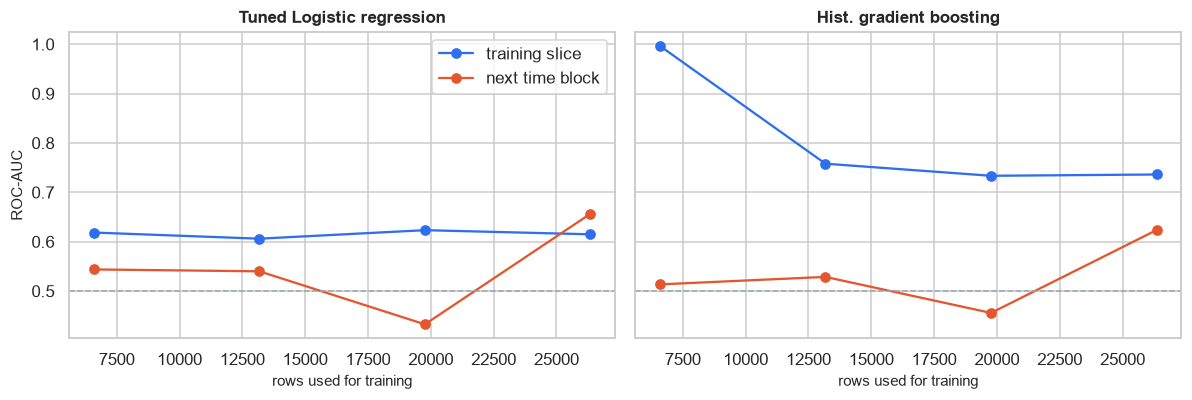

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for a, name in zip(ax, [TUNED_NAME, "Hist. gradient boosting"]):
    g = gap_detail[name]
    a.plot(g["train_rows"], g["train_auc"], "o-", color=C_MAIN, label="training slice")
    a.plot(g["train_rows"], g["valid_auc"], "o-", color=C_WARN, label="next time block")
    a.axhline(0.5, color=C_GREY, ls="--", lw=1); a.set_title(name); a.set_xlabel("rows used for training")
ax[0].set_ylabel("ROC-AUC"); ax[0].legend()
plt.tight_layout(); save_fig("fit_learning_curve")

**Reading.** The models fall into three groups.

* **Overfitting: random forest and boosting.** The random forest scores about 0.99 on its own training slice but about 0.52 on the next block, and boosting about 0.81 against 0.53. They memorise the past and gain nothing on the future, which fits their weaker hold-out results.
* **Little to no overfitting, but a low ceiling: logistic regression.** Training about 0.62 against validation about 0.54. The gap is small, yet even the training score is modest, so the pre-call inputs simply carry limited signal.
* **Underfitting: the MLP.** It scores only about 0.55 on its own training slice, so it barely learned the pattern with its current settings; its hold-out score should not be read as a ceiling for neural networks.

Conclusion: the weak forward-looking score is mainly a limit of the information available before the call plus drift, not an under-powered model. Adding model complexity makes the training score rise but not the validation score, which is why the simple, regularised logistic regression is the defensible choice.